# Research Methods for AI & Data Science: Paper Writing and Publishing

> **Who is this for?** MS/MPhil students (and curious engineers) who have results and now have to turn them into a paper or a thesis chapter, and then get it published. No previous writing experience is assumed: every section explains *what* a reader expects and *why*.
>
> **What you will learn**
> - How an ML paper is structured (IMRaD and the ML-paper variant), with a **good vs. weak example** and a **checklist** for every section
> - The 4-sentence abstract formula and the *problem → gap → contribution* introduction
> - Writing clearly: active voice, defined terms, consistent notation, and how to write mathematics (LaTeX source **and** rendered equations)
> - Publication-quality figures with matplotlib (fonts, sizes, colour-blind-safe palettes, vector PDF export, honest error bars) and LaTeX tables from a DataFrame (`df.to_latex`, booktabs)
> - LaTeX basics: a minimal paper skeleton, BibTeX, citation styles, Overleaf
> - Using AI writing tools responsibly
> - The publishing pipeline: choosing a venue, arXiv, double-blind anonymisation, peer review, rebuttals, camera-ready, posters, talks, open access
> - The thesis: chapters, working with a supervisor, the defence / viva
> - Plagiarism, self-plagiarism and authorship norms
>
> **Prerequisites:** [Python basics](../01_Python/01_basic.ipynb), [Matplotlib](../02_Data_Analysis/04_matplotlib.ipynb), [Statistics](../02_Data_Analysis/08_statistics.ipynb), [Maths notation bridge](../14_Mathematics/00_start_here_math_notation_bridge.ipynb), and the previous notebook of this module, [Reproducibility and research code](04_reproducibility_and_research_code.ipynb).
>
> **Time needed:** about 2–3 hours (reading + exercises).
>
> **Runs on:** CPU, no API key, no internet. All files are written to a temporary folder and deleted at the end.
>
> **Optional track:** this notebook is part of the university-level fundamentals track (module 24, *Research Methods for AI & Data Science*); recommended for BS/MS AI students, thesis writers and interview prep for research roles.

## Explained simply

A research paper is a short, carefully organised story that convinces other people that your finding is true and useful. It always answers the same questions in the same order: *what problem? what was missing? what did you do? what did you find? how sure are you? what are the limits?* Readers are busy, so most only read the title, the abstract and the figures; good writing puts the main message exactly there. After writing, you send the paper to a conference or journal, where other experts (the reviewers) check it before it is published.

- **Everyday example 1, a news article:** the headline and first paragraph tell you the whole story; the details come later. A paper's title and abstract work the same way.
- **Everyday example 2, a cooking video:** you show the finished dish first, then the ingredients, then the steps; if you only said "it tastes good", nobody would believe you without seeing it.

**Tiny concrete example:** the weak sentence *"Our method was much better."* becomes the strong sentence *"Our method answered 88 of 100 test questions correctly, compared with 84 for the old method."* The second one has numbers, says who did what, and a reader can check it.

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| Abstract | a 4-sentence summary: problem, gap, what we did, what we found | the first thing you read on arXiv or Google Scholar |
| Peer review | other experts check the paper before it is published | NeurIPS / ICML / ACL reviews; journal "major revision" letters |
| Plagiarism | presenting someone else's words or ideas as your own | similarity checkers (Turnitin) used by universities |

### Table of contents
1. Setup
2. Why writing is part of the research
3. The anatomy of a paper: IMRaD and the ML variant
4. Section by section: good vs. weak examples and checklists
5. Writing clearly (with a tiny style linter)
6. Writing mathematics
7. Figures for papers
8. Tables for papers: from a DataFrame to LaTeX
9. LaTeX basics: skeleton, BibTeX, citation styles, Overleaf
10. Using AI writing tools responsibly
11. The publishing process
12. The thesis
13. Plagiarism, self-plagiarism and authorship
14. How this connects to modern AI
15. Recap, practice problems, further reading

---
## 1. Setup

> 💡 **In plain English:** we load a few plotting and text tools and create a temporary folder.

We only need the standard library, numpy, pandas and matplotlib. Everything we write (PDF figures, `.tex` and `.bib` files) goes into a temporary folder.

In [1]:
import re                                   # regular expressions for our small text checkers
import shutil                               # delete the temporary folder at the end
import tempfile                             # a private scratch folder (never write into the repo)
import textwrap                             # pretty-print long strings
from collections import Counter             # counting words / n-grams
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display   # render generated markdown nicely

WORK = Path(tempfile.mkdtemp(prefix="paper_writing_"))   # all generated files live here
rng = np.random.default_rng(2026)                        # one seeded generator for the whole notebook
pd.set_option("display.max_colwidth", 120)
print("numpy", np.__version__, "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__)
print("scratch folder created:", WORK.exists())

numpy 2.4.6 | pandas 2.3.3 | matplotlib 3.11.0
scratch folder created: True


---
## 2. Why writing is part of the research

> 💡 **In plain English:** writing is how other people learn, check and use your research, so it is part of the work, not an extra.

**Analogy.** A paper is like the *map* of a hiking trail you discovered. The trail (your experiments) exists without the map, but nobody else can follow it, check it, or build on it. A wrong or confusing map is worse than none.

- Writing forces clarity: if you cannot state your contribution in one sentence, you probably do not know it yet. Many researchers **write the paper's outline before running the final experiments**, to see which evidence is missing (Simon Peyton Jones's well-known talk *How to write a great research paper* argues exactly this: "write first, then do the research").
- Readers are busy. Most of them read the **title → abstract → figures → conclusion**, and only then decide whether to read the rest. Design the paper for that path.
- Reviewers read your paper in a few hours, often alongside several others. Clarity directly affects acceptance.

> 🎓 **Exam / interview tip:** "What is the contribution of your thesis?" is the most common first question in a defence and in research interviews. Practise a one-sentence answer and a 30-second answer.

---
## 3. The anatomy of a paper: IMRaD and the ML variant

> 💡 **In plain English:** almost every ML paper has the same sections in the same order, each answering one question for the reader.

**IMRaD** (*Introduction, Methods, Results, and Discussion*) is the standard structure of empirical papers in science and medicine. ML conference papers use a variant with a few extra sections:

| ML paper section | IMRaD part | Reader's question it answers | Typical share of an 8–9 page conference paper |
|---|---|---|---|
| Title + Abstract | (front matter) | Should I read this? | ~200 words |
| 1 Introduction | I | What problem, why does it matter, what is new? | ~1 page |
| 2 Related work | I | How does this differ from what exists? | 0.5–1 page (sometimes placed before the conclusion) |
| 3 Method | M | What exactly did you do? Could I re-implement it? | 1.5–2.5 pages |
| 4 Experimental setup | M | Datasets, baselines, metrics, protocol, compute | ~1 page |
| 5 Results | R | What happened? With what uncertainty? | 1.5–2 pages |
| 6 Discussion / Limitations | D | What does it mean? When does it fail? | 0.5 page |
| 7 Conclusion | D | What should I remember? | a paragraph |
| Ethics / Broader impact statement | – | Who could be helped or harmed? | often required, may not count toward the page limit |
| References | – | Where do the ideas come from? | unlimited at most venues |
| Appendix / Supplementary | – | Proofs, extra results, hyper-parameters, checklists | unlimited at most venues |

The **hourglass** shape: start broad, narrow to your specific work, widen again at the end.

```
  Introduction      \_____ broad: the field, the problem, why it matters ______/
  Related work        \___ narrower: what others did, the gap ____________/
  Method                 \_ narrowest: exactly what YOU did ___________/
  Experiments/Results     |  your evidence, numbers with uncertainty   |
  Discussion             /‾ what it means, limitations ‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾\
  Conclusion          /‾‾‾ wider: implications, future work ‾‾‾‾‾‾‾‾‾‾‾‾‾\
```

> ⚠️ **Common mistake:** writing the paper in the *chronological* order of what you did ("first we tried X, it failed, then..."). A paper is an argument, not a diary. Order it by what the reader needs to believe your claim.

---
## 4. Section by section: good vs. weak examples and checklists

> 💡 **In plain English:** for each part of a paper, see a weak and a good version and a checklist.

Throughout this notebook we use one running example: a study asking *"Does class-balanced training improve minority-class recall on fraud-like tabular data?"* (you will run this study yourself in the next notebook). Numbers in the examples below are **illustrative**, not real results.

### 4.1 Title

| Weak | Good |
|---|---|
| *A Novel Approach for Improved Fraud Detection Using Machine Learning* | *Class-Balanced Training Raises Minority Recall but Not Ranking Quality on Imbalanced Tabular Data* |
| Vague ("novel", "improved", "using ML"); no finding | States the object, the finding and the scope; contains the searchable keywords |

**Checklist:** ☐ contains the key terms people will search for ☐ says *what* (and ideally the finding) ☐ no "novel", "towards", "a study of" padding ☐ short enough to read in one breath (≈ 8–15 words).

### 4.2 Abstract: the 4-sentence formula

A good abstract (≈ 150–250 words, check the venue limit) can be built from four sentences, each expanded if needed:

1. **Context / problem:** what problem, why it matters.
2. **Gap:** what is missing or wrong in current work.
3. **What we do:** your approach, in concrete terms.
4. **Result + implication:** the main quantitative finding and why it matters.

Below we build an abstract from its four parts and check it automatically.

In [2]:
def build_abstract(problem: str, gap: str, approach: str, result: str) -> str:
    """Join the four parts of the abstract formula into one paragraph."""
    parts = [problem, gap, approach, result]
    return " ".join(p.strip() for p in parts)


def check_abstract(text: str, max_words: int = 250) -> dict:
    """Simple automatic checks a careful author does by eye."""
    words = re.findall(r"[A-Za-z0-9%.\-]+", text)                          # rough word list
    sentences = [s for s in re.split(r"(?<=[.!?])\s+", text.strip()) if s]
    return {
        "words": len(words),
        "sentences": len(sentences),
        "within_limit": len(words) <= max_words,
        "has_a_number": bool(re.search(r"\d", text)),                      # a quantitative result?
        "uses_we": bool(re.search(r"\bwe\b", text, re.I)),                 # active voice, clear agency
        "hype_words": [w for w in ("novel", "groundbreaking", "revolutionary", "state-of-the-art")
                       if w in text.lower()],
    }


weak = ("Fraud is an important problem. In this paper a novel groundbreaking method is proposed "
        "which is shown to be very effective. Experiments were performed and good results were obtained.")

good = build_abstract(
    problem="Fraud detectors are trained on data where fewer than 5% of examples are fraudulent, "
            "so standard training tends to miss the rare class that matters most.",
    gap="Class-balanced loss weighting is a common remedy, but it is rarely compared against the simpler "
        "alternative of moving the decision threshold, and rarely evaluated with seed-level uncertainty.",
    approach="We compare unweighted, class-weighted and threshold-adjusted logistic regression on an "
             "imbalanced tabular benchmark using 10 seeds of nested 5-fold cross-validation, corrected "
             "resampled t-tests and Holm correction.",
    result="Class weighting raises minority recall from 0.37 to 0.73 (illustrative numbers) but lowers "
           "precision and slightly lowers ranking quality (PR-AUC), and a simple threshold shift does as well; "
           "practitioners should therefore tune the threshold for their cost trade-off rather than "
           "expect better ranking from re-weighting.",
)

print(textwrap.fill(good, 110), "\n")
print(pd.DataFrame({"weak": check_abstract(weak), "good": check_abstract(good)}))

Fraud detectors are trained on data where fewer than 5% of examples are fraudulent, so standard training tends
to miss the rare class that matters most. Class-balanced loss weighting is a common remedy, but it is rarely
compared against the simpler alternative of moving the decision threshold, and rarely evaluated with seed-
level uncertainty. We compare unweighted, class-weighted and threshold-adjusted logistic regression on an
imbalanced tabular benchmark using 10 seeds of nested 5-fold cross-validation, corrected resampled t-tests and
Holm correction. Class weighting raises minority recall from 0.37 to 0.73 (illustrative numbers) but lowers
precision and slightly lowers ranking quality (PR-AUC), and a simple threshold shift does as well;
practitioners should therefore tune the threshold for their cost trade-off rather than expect better ranking
from re-weighting. 

                                 weak  good
words                              29   124
sentences                      

**What just happened?** The weak abstract has no number, uses vague passive phrases ("is proposed", "were performed"), and hype words. The good one has four clear moves, a concrete protocol, a quantitative result and a take-away. An automatic check cannot judge *quality*, but it catches the most common problems.

**Abstract checklist:** ☐ the 4 moves are all present ☐ at least one concrete number ☐ no undefined acronyms ☐ no citations (most venues) ☐ within the word limit ☐ it matches what the paper actually shows (update it last!).

### 4.3 Introduction: problem → gap → contribution

A standard ML introduction has four paragraphs, and ends with **contribution bullets** (reviewers literally look for them):

| Paragraph | Job | Weak | Good |
|---|---|---|---|
| 1. Problem | Why should anyone care? | "Machine learning is widely used nowadays." | "Card-fraud models must catch rare fraudulent transactions; each missed case costs the issuer money and the customer trust." |
| 2. Gap | What is missing? | "However, there are some problems." | "Re-weighting is the default fix, but its benefit is usually measured with a single split and a fixed 0.5 threshold, which confounds *better ranking* with *a shifted threshold*." |
| 3. This paper | What do you do? | "We propose a novel method." | "We separate the two effects with an ablation that keeps the unweighted model but moves its threshold." |
| 4. Contributions | What exactly is new? | (missing) | three bullet points, each checkable |

Good contribution bullets are **specific and verifiable**:

- *We show, on 10 seeds of nested cross-validation, that class weighting raises minority recall but does not improve PR-AUC.*
- *We show that a threshold-moving ablation reproduces the recall gain at no training cost.*
- *We release code, configuration and seeds to reproduce every number.*

**Introduction checklist:** ☐ the problem is concrete ☐ the gap is stated explicitly ("however, ...") ☐ contributions are bullet points ☐ each contribution is backed by a section/figure ☐ no claim stronger than the evidence ☐ optional: a "teaser" figure on page 1.

### 4.4 Related work

| Weak ("laundry list") | Good (organised by theme, with contrast) |
|---|---|
| "Smith et al. did X. Lee et al. did Y. Kim et al. did Z." | "**Re-sampling methods.** Over-sampling (e.g. SMOTE) and under-sampling change the training distribution [..]. **Cost-sensitive learning** instead changes the loss [..]. **Unlike both**, we ask whether the reported gains survive a fair threshold comparison." |

**Checklist:** ☐ grouped by theme, not by paper ☐ every group ends with *how your work differs* ☐ fair to competitors (cite the strongest baselines) ☐ recent work included (search arXiv, Google Scholar, Semantic Scholar) ☐ every citation actually exists and says what you claim (see Section 10).

### 4.5 Method

| Weak | Good |
|---|---|
| "We used logistic regression with some regularisation and weights." | "We minimise the class-weighted cross-entropy (Eq. 1) with weights $w_c = n / (K\,n_c)$, L2 penalty $\lambda = 1/C$, and select $C \in \{0.01, 0.1, 1, 10\}$ by inner 3-fold CV on average precision." |

**Checklist:** ☐ another student could re-implement it from the text alone ☐ every symbol is defined ☐ design choices are justified ☐ a figure or pseudo-code for anything non-trivial ☐ hyper-parameters and their search ranges are listed (or in the appendix).

### 4.6 Experiments (setup)

**Checklist:** ☐ datasets with size, class balance, licence and split protocol ☐ baselines (including a trivial one, e.g. majority class) ☐ metrics and *why* they fit the question ☐ number of seeds/folds ☐ statistical test ☐ compute (CPU/GPU type, hours) ☐ software versions (see [notebook 04](04_reproducibility_and_research_code.ipynb)).

### 4.7 Results

| Weak | Good |
|---|---|
| "Our method is significantly better (Table 2)." | "Class weighting raises minority recall by 0.36 (95% CI [0.27, 0.45], corrected t-test, Holm-adjusted $p < 0.001$; Table 2), while PR-AUC drops by 0.05." |
| A table of 40 numbers with no bold, no uncertainty | A focused table: mean ± std over seeds, best in bold, the test used in the caption |

**Checklist:** ☐ every claim points to a figure/table ☐ uncertainty (std, CI) and number of runs ☐ "significant" only with a named statistical test ☐ effect sizes, not only p-values ☐ negative results reported honestly ☐ captions are self-contained (a reader should understand a figure from its caption alone).

### 4.8 Discussion and limitations

| Weak | Good |
|---|---|
| "Our method has no limitations." / no section | "Our data are synthetic and our model is linear; results may not hold for tree ensembles or for real fraud with concept drift. We test one imbalance ratio (≈ 3.6%)." |

Many venues (e.g. the NeurIPS paper checklist) explicitly ask for a limitations discussion and state that honest limitations should not be penalised.

**Checklist:** ☐ what assumptions could fail ☐ when the method does *not* work ☐ threats to validity (internal, external, construct, statistical; see notebook 06) ☐ computational cost.

### 4.9 Conclusion

**Weak:** copy-paste of the abstract. **Good:** 1 paragraph: the answer to the research question, the most important number, the practical take-away, and 1–2 concrete future-work directions.

### 4.10 Ethics / broader impact statement

Several venues ask for a statement on potential positive and negative societal impact, and some have an ethics review. For our example: *"Better fraud recall protects customers, but more false positives can block legitimate transactions; such errors may fall unevenly across customer groups, so deployment should include a fairness audit."* See [Bias & fairness](../19_AI_Ethics_and_Safety/01_bias_fairness.ipynb) and [Responsible AI](../19_AI_Ethics_and_Safety/04_responsible_ai.ipynb) for how to do the audit itself.

**Checklist:** ☐ who benefits, who could be harmed ☐ misuse potential ☐ data consent, privacy and licences ☐ mitigation.

### 4.11 Appendix / supplementary material

Proofs, full hyper-parameter tables, extra datasets, the reproducibility checklist and per-seed results. **Rule:** the main paper must stand alone; reviewers are not obliged to read the appendix.

> 🎓 **Exam / interview tip:** a classic question is "In which order do you write the sections?" A common answer: figures and tables first (they are the evidence), then method and experiments, then results, then introduction, and the **abstract and title last**.

---
## 5. Writing clearly

> 💡 **In plain English:** short sentences, say who did what, define every term, and give numbers instead of vague words.

| Principle | Weak | Better |
|---|---|---|
| **Active voice** (say who did what) | "Experiments were performed." | "We ran five experiments." |
| **Define terms before use** | "We use PR-AUC." | "We use the area under the precision–recall curve (PR-AUC)." |
| **One term per concept** | "classifier ... model ... predictor ... network" for one thing | pick *model* and keep it |
| **Consistent notation** | $x$ is a vector on page 2 and a scalar on page 5 | a notation table; bold $\mathbf{x}$ for vectors everywhere |
| **Concrete numbers** | "much better", "significantly" (no test) | "0.12 higher (95% CI [0.08, 0.16])" |
| **Short sentences** | 60-word sentences with three clauses | one idea per sentence |
| **No hedging stacks** | "It may possibly be somewhat suggested that..." | "This suggests that..." |

Passive voice is not *forbidden* (it is fine when the actor is irrelevant: "Samples were collected in 2024"), but overusing it hides who did what.

We now write a **tiny style linter** that flags common problems. It uses simple rules (regular expressions), so it has false positives; real tools (e.g. LanguageTool, Vale, `write-good`) are more careful, but the idea is the same.

In [3]:
WEASEL = ["very", "clearly", "obviously", "extremely", "quite", "fairly", "really", "basically", "novel"]
# "be-verb + past participle" is a rough test for passive voice
PASSIVE = re.compile(r"\b(is|are|was|were|be|been|being)\s+(\w+ly\s+)?(\w+ed|shown|done|made|seen|given|taken|found)\b", re.I)


def lint(text: str) -> pd.DataFrame:
    """Return one row per issue found in `text`."""
    issues = []
    for m in PASSIVE.finditer(text):                                     # 1) passive constructions
        issues.append(("passive voice?", m.group(0)))
    for w in WEASEL:                                                      # 2) weasel / hype words
        for m in re.finditer(rf"\b{w}\b", text, re.I):
            issues.append(("weasel/hype word", m.group(0)))
    seen = set()                                                          # 3) acronyms: defined as "(ABC)"?
    for m in re.finditer(r"\b[A-Z][A-Za-z\-]*[A-Z]\b", text):
        acr = m.group(0)
        defined_so_far = f"({acr})" in text[: m.end() + 1]                # defined here or earlier
        if not defined_so_far and acr not in seen:
            issues.append(("acronym used before definition", acr))
        seen.add(acr)
    if re.search(r"\bsignificant(ly)?\b", text, re.I) and not re.search(r"\b(test|p\s*[<=])", text, re.I):
        issues.append(("'significant' without a statistical test", "significant"))
    for s in re.split(r"(?<=[.!?])\s+", text):                           # 4) very long sentences
        n = len(s.split())
        if n > 35:
            issues.append((f"long sentence ({n} words)", s[:50] + "..."))
    return pd.DataFrame(issues, columns=["issue", "text"])


weak_para = ("The PR-AUC was clearly improved by the novel method and it was shown that results are very "
             "significantly better. Experiments were performed on SMOTE-resampled data.")
good_para = ("We measure ranking quality with the area under the precision-recall curve (PR-AUC). "
             "Class weighting lowers PR-AUC by 0.05 (corrected t-test, p = 0.001).")

print("WEAK paragraph:")
display(lint(weak_para))
print("GOOD paragraph:")
display(lint(good_para))

WEAK paragraph:


,issue,text
0,passive voice?,was clearly improved
1,passive voice?,was shown
2,passive voice?,were performed
3,weasel/hype word,very
4,weasel/hype word,clearly
5,weasel/hype word,novel
6,acronym used before definition,PR-AUC
7,acronym used before definition,SMOTE
8,'significant' without a statistical test,significant


GOOD paragraph:


,issue,text


**What just happened?** The linter found passive constructions, hype words, the acronyms *PR-AUC* and *SMOTE* used without definition, and "significantly" without a test in the weak paragraph, and nothing in the good one. **Cost:** each rule scans the text once, so the linter runs in $O(n \cdot r)$ time for $n$ characters and $r$ rules.

> ⚠️ **Common mistake:** "significant" is a technical word in a results section. Use it only for a statistical test you name, and report the effect size too. Otherwise write "large", "noticeable" or give the number.

---
## 6. Writing mathematics

> 💡 **In plain English:** write formulas with standard symbols, explain every symbol, and check that the formula matches your code.

Rules used by most ML papers:

| Object | Convention | LaTeX | Rendered |
|---|---|---|---|
| scalar | italic lowercase | `x, \lambda` | $x, \lambda$ |
| vector | bold lowercase | `\mathbf{x}` | $\mathbf{x}$ |
| matrix | bold uppercase | `\mathbf{W}` | $\mathbf{W}$ |
| set | calligraphic / blackboard | `\mathcal{D}, \mathbb{R}^d` | $\mathcal{D}, \mathbb{R}^d$ |
| estimate | hat | `\hat{y}` | $\hat{y}$ |
| expectation | | `\mathbb{E}_{x \sim p}[f(x)]` | $\mathbb{E}_{x \sim p}[f(x)]$ |

1. **Define every symbol** right after (or before) its first use: "where $n_c$ is the number of training examples of class $c$".
2. **Equations are part of sentences:** they get commas and full stops.
3. **Number only equations you refer to**, and refer to them as "Eq. (1)".
4. **Do not reuse a symbol** for two things; keep a notation table in the appendix for long papers.
5. Use `\operatorname{...}` or `\mathrm{...}` for multi-letter names (`\mathrm{softmax}`, not `softmax`, which would render as a product of italic letters).

Here is the LaTeX **source** you would type in the paper for the weighted logistic loss of our running example:

```latex
Given training data $\mathcal{D} = \{(\mathbf{x}_i, y_i)\}_{i=1}^{n}$ with $y_i \in \{0, 1\}$,
we minimise the class-weighted cross-entropy
\begin{equation}
  \mathcal{L}(\mathbf{w}) = -\frac{1}{n} \sum_{i=1}^{n} w_{y_i}
    \bigl[\, y_i \log \sigma(\mathbf{w}^\top \mathbf{x}_i)
      + (1 - y_i) \log\bigl(1 - \sigma(\mathbf{w}^\top \mathbf{x}_i)\bigr) \bigr]
    + \frac{\lambda}{2} \lVert \mathbf{w} \rVert_2^2 ,
  \label{eq:loss}
\end{equation}
where $\sigma(z) = 1/(1 + e^{-z})$ is the logistic function, $\lambda \ge 0$ is the L2 penalty,
and $w_c = n / (2\, n_c)$ with $n_c$ the number of training examples of class $c$.
```

And this is how it **renders** (Jupyter uses MathJax, which understands the same syntax):

Given training data $\mathcal{D} = \{(\mathbf{x}_i, y_i)\}_{i=1}^{n}$ with $y_i \in \{0, 1\}$, we minimise the class-weighted cross-entropy

$$
\mathcal{L}(\mathbf{w}) = -\frac{1}{n} \sum_{i=1}^{n} w_{y_i}
\bigl[\, y_i \log \sigma(\mathbf{w}^\top \mathbf{x}_i) + (1 - y_i) \log\bigl(1 - \sigma(\mathbf{w}^\top \mathbf{x}_i)\bigr) \bigr]
+ \frac{\lambda}{2} \lVert \mathbf{w} \rVert_2^2 , \qquad (1)
$$

where $\sigma(z) = 1/(1 + e^{-z})$ is the logistic function, $\lambda \ge 0$ is the L2 penalty, and $w_c = n / (2\, n_c)$ with $n_c$ the number of training examples of class $c$. (With $w_c$ defined this way, both classes contribute equal total weight; this is exactly scikit-learn's `class_weight="balanced"` for $K=2$ classes, $w_c = n/(K\,n_c)$.)

Let us check that last claim numerically, because **every formula in a paper should match the code**.

In [4]:
from sklearn.utils.class_weight import compute_class_weight

y_demo = np.array([0] * 96 + [1] * 4)                      # 4% positives, like fraud
n, K = len(y_demo), 2
by_formula = np.array([n / (K * np.sum(y_demo == c)) for c in (0, 1)])           # w_c = n / (K n_c)
by_sklearn = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_demo)
print("formula :", by_formula.round(4))
print("sklearn :", by_sklearn.round(4))
assert np.allclose(by_formula, by_sklearn)
# total weight per class is equal: n_c * w_c = n / K for every class
print("total weight per class:", [float(np.sum(y_demo == c) * by_formula[c]) for c in (0, 1)])

formula : [ 0.5208 12.5   ]
sklearn : [ 0.5208 12.5   ]
total weight per class: [50.0, 50.0]


**What just happened?** The formula in the paper and the library agree (weights ≈ 0.52 for the majority class and 12.5 for the minority class), and both classes now carry the same total weight (50 each). Small checks like this catch the frequent mismatch "the paper says one thing, the code does another".

Matplotlib can render the same LaTeX-like syntax (*mathtext*) inside figures, without a LaTeX installation:

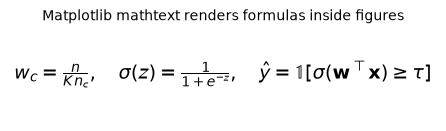

In [5]:
fig, ax = plt.subplots(figsize=(5.5, 1.2))
ax.axis("off")
ax.text(0.5, 0.5, r"$w_c = \frac{n}{K\,n_c}, \quad \sigma(z) = \frac{1}{1+e^{-z}}, \quad "
        r"\hat{y} = \mathbb{1}[\sigma(\mathbf{w}^\top\mathbf{x}) \geq \tau]$",
        ha="center", va="center", fontsize=14)
ax.set_title("Matplotlib mathtext renders formulas inside figures", fontsize=10)
plt.show()

---
## 7. Figures for papers

> 💡 **In plain English:** draw figures at their final size, readable, colour-blind-friendly and with honest error bars.

A good paper figure is **readable when printed at its final size**, **honest** about uncertainty, **colour-blind safe** and **vector** (so it stays sharp when zoomed).

| Setting | Typical value | Why |
|---|---|---|
| Width | one column ≈ 3.25–3.5 in; full width ≈ 5.5–7 in (check `\columnwidth` / `\textwidth` of the template) | draw at the final size, so fonts are not shrunk |
| Font size | 8–10 pt (same as or slightly smaller than the caption) | readable on paper |
| Format | PDF (or SVG/EPS) for plots; PNG/JPG only for photos | vector graphics scale without blur |
| Fonts in PDF | embed TrueType (`pdf.fonttype = 42`) | some venues reject Type-3 fonts |
| Colours | a colour-blind-safe palette (e.g. Okabe–Ito) + different markers/line styles | about 1 in 12 men has a colour-vision deficiency; many readers print in grey |
| Error bars | say *what* they are (std, SEM or 95% CI) and over how many runs | the meaning changes the conclusion |

The **Okabe–Ito** palette (Okabe & Ito, 2008) was designed to stay distinguishable for the common colour-vision deficiencies. We put the style in one function so all figures of a paper look the same.

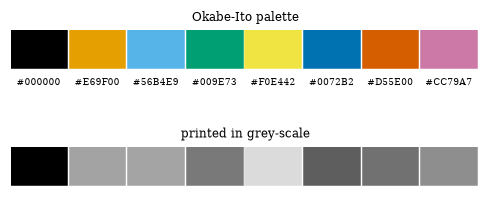

{'#000000': 0.0, '#E69F00': 0.64, '#56B4E9': 0.64, '#009E73': 0.48, '#F0E442': 0.86, '#0072B2': 0.37, '#D55E00': 0.44, '#CC79A7': 0.56}


In [6]:
OKABE_ITO = ["#000000", "#E69F00", "#56B4E9", "#009E73", "#F0E442", "#0072B2", "#D55E00", "#CC79A7"]


def paper_style(font_size: int = 9) -> None:
    """Global matplotlib settings for publication figures (call once at the top of a script)."""
    plt.rcParams.update({
        "font.size": font_size,                  # body text of the figure
        "axes.titlesize": font_size,
        "axes.labelsize": font_size,
        "xtick.labelsize": font_size - 1,
        "ytick.labelsize": font_size - 1,
        "legend.fontsize": font_size - 1,
        "font.family": "serif",                  # matches most LaTeX templates (Times / Computer Modern)
        "mathtext.fontset": "dejavuserif",
        "axes.prop_cycle": matplotlib.cycler(color=OKABE_ITO[1:] + OKABE_ITO[:1]),
        "axes.spines.top": False,                # less ink, same information
        "axes.spines.right": False,
        "pdf.fonttype": 42,                      # embed TrueType fonts in PDF (no Type 3)
        "ps.fonttype": 42,
        "savefig.bbox": "tight",
        "savefig.dpi": 300,                      # only matters for raster formats (PNG)
        "figure.dpi": 110,
    })


paper_style()

# Show the palette with its luminance (lightness), which is what survives grey-scale printing
def luminance(hex_colour: str) -> float:
    r, g, b = matplotlib.colors.to_rgb(hex_colour)
    return 0.2126 * r + 0.7152 * g + 0.0722 * b   # Rec. 709 luma weights (approximate perceived lightness)

fig, axes = plt.subplots(2, 1, figsize=(5.5, 2.1))
fig.subplots_adjust(hspace=0.9)
for ax, gray in zip(axes, (False, True)):
    for i, c in enumerate(OKABE_ITO):
        colour = str(luminance(c)) if gray else c                      # matplotlib accepts "0.4" as a grey level
        ax.add_patch(plt.Rectangle((i, 0), 0.95, 1, color=colour))
        if not gray:
            ax.text(i + 0.47, -0.25, c, ha="center", va="top", fontsize=6)
    ax.set_xlim(0, len(OKABE_ITO)); ax.set_ylim(-0.6, 1); ax.axis("off")
    ax.set_title("printed in grey-scale" if gray else "Okabe-Ito palette", fontsize=8)
plt.show()
print({c: round(luminance(c), 2) for c in OKABE_ITO})

**What just happened?** We defined one style function (fonts, sizes, palette, font embedding) and looked at the palette in colour and in grey. Some pairs (for example the orange `#E69F00` and the sky-blue `#56B4E9`) have almost the same lightness. They look different in colour but nearly the same grey. **So use markers or line styles as well as colour**, which is what we do next.

### 7.1 Error bars: std, SEM or CI?

We make up (simulate) the scores of three methods over 10 seeds on four datasets. **These are demo numbers made with a random generator, not real results.** Then we plot the *same* data with three kinds of error bar.

In [7]:
methods = ["Baseline", "Weighted", "Threshold"]
datasets = ["D1", "D2", "D3", "D4"]
true_means = {"Baseline": [0.62, 0.70, 0.55, 0.81], "Weighted": [0.71, 0.74, 0.66, 0.83],
              "Threshold": [0.70, 0.75, 0.64, 0.82]}
rows = []
for m in methods:
    for d, mu in zip(datasets, true_means[m]):
        for seed in range(10):
            rows.append({"method": m, "dataset": d, "seed": seed,
                         "score": float(np.clip(rng.normal(mu, 0.03), 0, 1))})    # simulated score
scores = pd.DataFrame(rows)

summary = scores.groupby(["method", "dataset"])["score"].agg(["mean", "std", "count"]).reset_index()
summary["sem"] = summary["std"] / np.sqrt(summary["count"])                     # standard error of the mean
from scipy import stats
t_crit = stats.t.ppf(0.975, df=summary["count"] - 1)                            # t quantile for a 95% CI
summary["ci95"] = t_crit * summary["sem"]                                       # half-width of the 95% CI
print(summary.round(3).head(4))

     method dataset   mean    std  count    sem   ci95
0  Baseline      D1  0.616  0.026     10  0.008  0.019
1  Baseline      D2  0.698  0.019     10  0.006  0.013
2  Baseline      D3  0.556  0.028     10  0.009  0.020
3  Baseline      D4  0.817  0.027     10  0.009  0.019


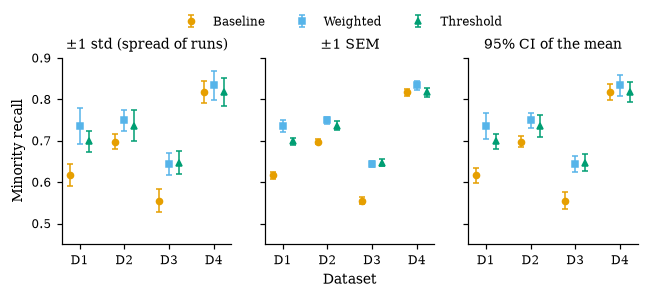

In [8]:
def grouped_errorbars(ax, summary, err_col, title):
    """Dot + error-bar plot: one marker style AND one colour per method (colour-blind and grey-scale safe)."""
    markers = {"Baseline": "o", "Weighted": "s", "Threshold": "^"}
    x = np.arange(len(datasets))
    for k, m in enumerate(methods):
        s = summary[summary.method == m].set_index("dataset").loc[datasets]
        ax.errorbar(x + (k - 1) * 0.22, s["mean"], yerr=s[err_col], fmt=markers[m], ms=4,
                    capsize=2, lw=1, label=m)
    ax.set_xticks(x, datasets)
    ax.set_title(title)
    ax.set_ylim(0.45, 0.9)


fig, axes = plt.subplots(1, 3, figsize=(6.75, 2.2), sharey=True)      # full-width figure of a 2-column paper
grouped_errorbars(axes[0], summary, "std", "±1 std (spread of runs)")
grouped_errorbars(axes[1], summary, "sem", "±1 SEM")
grouped_errorbars(axes[2], summary, "ci95", "95% CI of the mean")
axes[0].set_ylabel("Minority recall")
axes[1].set_xlabel("Dataset")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.1))
plt.show()

**What just happened?** Same data, three different pictures. The **std** bars show how much single runs vary; the **SEM** bars are $\sqrt{10} \approx 3.2$ times smaller; the **95% CI** bars are $t_{0.975,9} \approx 2.26$ times the SEM. A reader who does not know which one you used cannot interpret the plot, so **state it in the caption**, e.g. *"Mean over 10 seeds; error bars are 95% confidence intervals (t-distribution)."*

> ⚠️ **Common mistake:** concluding "the bars overlap, so there is no difference" (or the opposite). Overlap of 95% CIs of two *separate* means is not a significance test, and paired designs (same seeds/folds for both methods) need a paired test on the differences (see notebook 06).

### 7.2 Exporting a vector PDF

We save the figure as PDF (and SVG) into the temp folder, check the file is a real PDF, and check that the fonts are embedded as TrueType (`/FontFile2`) rather than Type 3.

In [9]:
fig, ax = plt.subplots(figsize=(3.25, 2.2))                 # one column of a two-column paper
grouped_errorbars(ax, summary, "ci95", "")
ax.set_xlabel("Dataset"); ax.set_ylabel("Minority recall")
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.15), handletextpad=0.2, columnspacing=0.8)
pdf_path = WORK / "fig_recall.pdf"
svg_path = WORK / "fig_recall.svg"
fig.savefig(pdf_path)                                       # vector: stays sharp at any zoom
fig.savefig(svg_path)
plt.close(fig)

raw = pdf_path.read_bytes()
print("PDF header       :", raw[:5])                        # every PDF file starts with %PDF-
print("PDF size (KB)    :", round(len(raw) / 1024, 1))
print("TrueType embedded:", b"/FontFile2" in raw, "| Type 3 fonts:", b"/Subtype /Type3" in raw)
print("files written    :", sorted(p.name for p in WORK.iterdir()))

PDF header       : b'%PDF-'
PDF size (KB)    : 12.7
TrueType embedded: True | Type 3 fonts: False
files written    : ['fig_recall.pdf', 'fig_recall.svg']


In the LaTeX source you would include it with `\includegraphics[width=\columnwidth]{fig_recall.pdf}`. Because we drew it at 3.25 in wide, the 9 pt fonts in the figure stay 9 pt in the paper.

**Figure checklist:** ☐ drawn at final size ☐ fonts ≥ 7–8 pt ☐ axes labelled with units ☐ error bars explained in the caption ☐ colour-blind-safe palette **and** markers/line styles ☐ vector format ☐ no chart junk (3-D bars, heavy grids, shadows) ☐ the caption states the take-away ("Weighting raises recall on all four datasets").

---
## 8. Tables for papers: from a DataFrame to LaTeX

> 💡 **In plain English:** let code produce the results table so the numbers in the paper can never be typed wrongly.

Results tables should be generated **from code**, never typed by hand (hand-typed numbers are a classic source of errors). `DataFrame.to_latex()` writes a LaTeX `tabular`; by default it uses the rules of the **booktabs** package (`\toprule`, `\midrule`, `\bottomrule`), the standard in most ML papers (add `\usepackage{booktabs}` to the preamble). We format "mean ± std" cells and **bold the best mean per dataset**.

In [10]:
pivot_mean = summary.pivot(index="method", columns="dataset", values="mean").loc[methods]
pivot_std = summary.pivot(index="method", columns="dataset", values="std").loc[methods]


def latex_cell(mean: float, std: float, best: bool) -> str:
    text = f"{mean:.3f} \\pm {std:.3f}"
    return f"$\\mathbf{{{mean:.3f}}} \\pm {std:.3f}$" if best else f"${text}$"


table = pd.DataFrame(index=methods, columns=datasets, dtype=object)
for d in datasets:
    best_method = pivot_mean[d].idxmax()                                 # the best mean in this column
    for m in methods:
        table.loc[m, d] = latex_cell(pivot_mean.loc[m, d], pivot_std.loc[m, d], m == best_method)
table = table.reset_index(names="Method")      # the method names become a normal first column

latex = table.to_latex(
    index=False,
    escape=False,                    # we wrote LaTeX math ourselves, do not escape the $ and \
    column_format="l" + "c" * len(datasets),
    caption="Minority recall (mean $\\pm$ std over 10 seeds; synthetic demo data). Best mean in bold.",
    label="tab:recall",
    position="t",
)
(WORK / "table_recall.tex").write_text(latex)
print(latex)
assert "\\toprule" in latex and "\\bottomrule" in latex       # booktabs rules are there

\begin{table}[t]
\caption{Minority recall (mean $\pm$ std over 10 seeds; synthetic demo data). Best mean in bold.}
\label{tab:recall}
\begin{tabular}{lcccc}
\toprule
Method & D1 & D2 & D3 & D4 \\
\midrule
Baseline & $0.616 \pm 0.026$ & $0.698 \pm 0.019$ & $0.556 \pm 0.028$ & $0.817 \pm 0.027$ \\
Weighted & $\mathbf{0.736} \pm 0.043$ & $\mathbf{0.749} \pm 0.025$ & $0.644 \pm 0.025$ & $\mathbf{0.833} \pm 0.035$ \\
Threshold & $0.698 \pm 0.025$ & $0.736 \pm 0.037$ & $\mathbf{0.647} \pm 0.029$ & $0.817 \pm 0.034$ \\
\bottomrule
\end{tabular}
\end{table}



**What just happened?** One call produced a complete `table` environment with caption, label and booktabs rules. In the paper: `\input{table_recall.tex}`. If you re-run the experiment, the table updates itself, so the paper and the code can never disagree.

**Table checklist:** ☐ generated by code ☐ same number of decimals in a column (3 significant digits is usually enough) ☐ units and direction ("↑ higher is better") in the header ☐ uncertainty and number of runs in the caption ☐ best result in bold *only if* the difference is meaningful ☐ no vertical lines (booktabs style).

---
## 9. LaTeX basics: skeleton, BibTeX, citation styles, Overleaf

> 💡 **In plain English:** LaTeX is the typesetting language of most ML papers; references live in a separate BibTeX file.

**LaTeX** is the typesetting system used for most ML papers and many theses. You write plain text with commands, and a compiler (`pdflatex`, `xelatex`, `lualatex`, usually driven by `latexmk`) produces the PDF. Every venue provides a **template** (a style file such as `neurips_20XX.sty`, `icml20XX.sty`, or a class such as `acmart`/`IEEEtran`); always download the **current year's** template from the venue's call for papers.

**Overleaf** is a widely used online LaTeX editor: no installation, real-time collaboration (handy with a supervisor), comments, history, and ready-made templates for most venues and many university theses. Compiling is not needed for this notebook; we only write the files.

Below is a minimal paper skeleton with the ML-paper structure. The `\usepackage{neurips_20XX}` line is commented out because the style file comes from the venue.

In [11]:
MAIN_TEX = r"""
\documentclass{article}
% \usepackage{neurips_20XX}        % venue style file (download the current one); option [final] for camera-ready
\usepackage[utf8]{inputenc}
\usepackage{amsmath,amssymb}       % maths
\usepackage{booktabs}              % \toprule \midrule \bottomrule
\usepackage{graphicx}              % \includegraphics
\usepackage[numbers]{natbib}       % \citet{} and \citep{}
\usepackage{hyperref}              % clickable links (load late)

\title{Class-Balanced Training Raises Minority Recall but Not Ranking Quality}
\author{Anonymous Author(s)}       % double-blind submission: no names!

\begin{document}
\maketitle

\begin{abstract}
Fraud detectors are trained on data where fewer than 5\% of examples are fraudulent ...
\end{abstract}

\section{Introduction}\label{sec:intro}
Transformers \citep{vaswani2017attention} and residual networks \citep{he2016resnet} ...
Following \citet{mitchell2019modelcards}, we release a model card.
Our contributions are:
\begin{itemize}
  \item We show that ...
\end{itemize}

\section{Related Work}\label{sec:related}
\section{Method}\label{sec:method}
We minimise Eq.~\eqref{eq:loss} ...
\begin{equation}
  \mathcal{L}(\mathbf{w}) = -\frac{1}{n}\sum_{i=1}^{n} w_{y_i} \ell(\mathbf{w}; \mathbf{x}_i, y_i)
  + \frac{\lambda}{2}\lVert\mathbf{w}\rVert_2^2 . \label{eq:loss}
\end{equation}

\section{Experiments}\label{sec:experiments}
\input{table_recall.tex}
\begin{figure}[t]
  \centering
  \includegraphics[width=\columnwidth]{fig_recall.pdf}
  \caption{Minority recall per dataset. Mean over 10 seeds; error bars are 95\% CIs.}
  \label{fig:recall}
\end{figure}

\section{Results}\label{sec:results}
As Table~\ref{tab:recall} and Figure~\ref{fig:recall} show, ...

\section{Limitations}\label{sec:limitations}
\section{Conclusion}\label{sec:conclusion}
\section*{Broader Impact}
% \section*{Acknowledgements}      % add only in the camera-ready version (would break anonymity)

\bibliographystyle{plainnat}
\bibliography{refs}

\appendix
\section{Hyper-parameters and Additional Results}\label{app:extra}
\end{document}
""".strip()

(WORK / "main.tex").write_text(MAIN_TEX)
print(MAIN_TEX[:900], "\n...")

\documentclass{article}
% \usepackage{neurips_20XX}        % venue style file (download the current one); option [final] for camera-ready
\usepackage[utf8]{inputenc}
\usepackage{amsmath,amssymb}       % maths
\usepackage{booktabs}              % \toprule \midrule \bottomrule
\usepackage{graphicx}              % \includegraphics
\usepackage[numbers]{natbib}       % \citet{} and \citep{}
\usepackage{hyperref}              % clickable links (load late)

\title{Class-Balanced Training Raises Minority Recall but Not Ranking Quality}
\author{Anonymous Author(s)}       % double-blind submission: no names!

\begin{document}
\maketitle

\begin{abstract}
Fraud detectors are trained on data where fewer than 5\% of examples are fraudulent ...
\end{abstract}

\section{Introduction}\label{sec:intro}
Transformers \citep{vaswani2017attention} and residual networks \citep{he2016resnet} ...
Following \cit 
...


### 9.1 BibTeX

References live in a `.bib` file; LaTeX + BibTeX (or `biber` with `biblatex`) format them in the venue's style. Every entry has a **type** (`@article`, `@inproceedings`, `@book`, `@misc` for arXiv preprints), a **key** you cite with, and fields. The four entries below are real, well-known papers.

**Tips:** copy BibTeX from the publisher, DBLP or the venue's proceedings page rather than from automatically generated sources, cite the **published version** instead of the arXiv version when one exists, and protect capitals with braces (`{BERT}`), otherwise some styles lower-case them.

In [12]:
REFS_BIB = r"""
@inproceedings{vaswani2017attention,
  title     = {Attention Is All You Need},
  author    = {Vaswani, Ashish and Shazeer, Noam and Parmar, Niki and Uszkoreit, Jakob and Jones, Llion and Gomez, Aidan N. and Kaiser, {\L}ukasz and Polosukhin, Illia},
  booktitle = {Advances in Neural Information Processing Systems},
  volume    = {30},
  year      = {2017}
}

@inproceedings{he2016resnet,
  title     = {Deep Residual Learning for Image Recognition},
  author    = {He, Kaiming and Zhang, Xiangyu and Ren, Shaoqing and Sun, Jian},
  booktitle = {Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition (CVPR)},
  pages     = {770--778},
  year      = {2016}
}

@inproceedings{mitchell2019modelcards,
  title     = {Model Cards for Model Reporting},
  author    = {Mitchell, Margaret and Wu, Simone and Zaldivar, Andrew and Barnes, Parker and Vasserman, Lucy and Hutchinson, Ben and Spitzer, Elena and Raji, Inioluwa Deborah and Gebru, Timnit},
  booktitle = {Proceedings of the Conference on Fairness, Accountability, and Transparency (FAT*)},
  pages     = {220--229},
  year      = {2019}
}

@article{gebru2021datasheets,
  title   = {Datasheets for Datasets},
  author  = {Gebru, Timnit and Morgenstern, Jamie and Vecchione, Briana and Vaughan, Jennifer Wortman and Wallach, Hanna and Daum{\'e} III, Hal and Crawford, Kate},
  journal = {Communications of the ACM},
  volume  = {64},
  number  = {12},
  pages   = {86--92},
  year    = {2021}
}
""".strip()
(WORK / "refs.bib").write_text(REFS_BIB)


def parse_bib(text: str) -> dict:
    """A deliberately tiny BibTeX parser (one field per line), enough for our own clean .bib files.
    Real projects use a proper parser (e.g. the `bibtexparser` package) or let LaTeX do it."""
    entries = {}
    for m in re.finditer(r"@(\w+)\{([^,]+),(.*?)\n\}", text, re.S):
        etype, key, body = m.group(1).lower(), m.group(2).strip(), m.group(3)
        fields = dict(re.findall(r"(\w+)\s*=\s*\{(.*)\},?\s*$", body, re.M))
        entries[key] = {"type": etype, **fields}
    return entries


BIB = parse_bib(REFS_BIB)
print(pd.DataFrame(BIB).T[["type", "year", "title"]])

                                 type  year  \
vaswani2017attention    inproceedings  2017   
he2016resnet            inproceedings  2016   
mitchell2019modelcards  inproceedings  2019   
gebru2021datasheets           article  2021   

                                                               title  
vaswani2017attention                       Attention Is All You Need  
he2016resnet            Deep Residual Learning for Image Recognition  
mitchell2019modelcards               Model Cards for Model Reporting  
gebru2021datasheets                          Datasheets for Datasets  


### 9.2 Citation styles

The same entry looks different in different styles. The two families you will meet:

| Family | In-text | Reference list | Used by |
|---|---|---|---|
| **Numeric** (e.g. IEEE, `plain`, `unsrt`) | "... transformers [1]" | ordered by number | IEEE venues, many CS journals, some ML templates |
| **Author–year** (e.g. APA, `plainnat`, Chicago) | "... transformers (Vaswani et al., 2017)" or "Vaswani et al. (2017) show ..." | alphabetical | NeurIPS/ICML/ICLR templates commonly use natbib author–year; social sciences use APA |

With **natbib**, `\citet{key}` gives *"Vaswani et al. (2017)"* (textual, part of the sentence) and `\citep{key}` gives *"(Vaswani et al., 2017)"* (parenthetical). A citation is **not a noun**: write "Vaswani et al. (2017) proposed ...", not "[1] proposed ...".

Here is a toy formatter that renders our parsed entries in both families (real styles have many more rules):

In [13]:
def clean(s: str) -> str:
    """Remove BibTeX braces and accents commands for display."""
    s = s.replace(r"{\L}", "Ł").replace(r"{\'e}", "é")
    return re.sub(r"[{}]", "", s)


def surnames(author_field: str) -> list:
    return [clean(a.split(",")[0].strip()) for a in author_field.split(" and ")]


def cite_author_year(key: str, textual: bool = False) -> str:
    e = BIB[key]; names = surnames(e["author"])
    who = names[0] if len(names) == 1 else (f"{names[0]} and {names[1]}" if len(names) == 2 else f"{names[0]} et al.")
    return f"{who} ({e['year']})" if textual else f"({who}, {e['year']})"


def reference_numeric(i: int, key: str) -> str:
    e = BIB[key]
    names = surnames(e["author"])
    authors = ", ".join(names[:3]) + (" et al." if len(names) > 3 else "")
    venue = clean(e.get("booktitle", e.get("journal", "")))
    return f"[{i}] {authors}, \"{clean(e['title'])},\" {venue}, {e['year']}."


order = ["vaswani2017attention", "he2016resnet", "mitchell2019modelcards", "gebru2021datasheets"]
print("Author-year in text :", cite_author_year("vaswani2017attention", textual=True), "show that ...;",
      "... as in", cite_author_year("he2016resnet"))
print("Numeric in text     : ... transformers [1] and residual networks [2]\n")
for i, k in enumerate(order, 1):
    print(reference_numeric(i, k))

Author-year in text : Vaswani et al. (2017) show that ...; ... as in (He et al., 2016)
Numeric in text     : ... transformers [1] and residual networks [2]

[1] Vaswani, Shazeer, Parmar et al., "Attention Is All You Need," Advances in Neural Information Processing Systems, 2017.
[2] He, Zhang, Ren et al., "Deep Residual Learning for Image Recognition," Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition (CVPR), 2016.
[3] Mitchell, Wu, Zaldivar et al., "Model Cards for Model Reporting," Proceedings of the Conference on Fairness, Accountability, and Transparency (FAT*), 2019.
[4] Gebru, Morgenstern, Vecchione et al., "Datasheets for Datasets," Communications of the ACM, 2021.


**What just happened?** One `.bib` database, two citation styles. In LaTeX you switch style by changing a single line (`\bibliographystyle{...}` or the `biblatex` `style=` option), never by editing references by hand. Reference managers (Zotero, Mendeley, JabRef) export `.bib` files and keep your library organised; Zotero with the *Better BibTeX* add-on is a popular free combination.

We can also **lint the LaTeX source** for problems reviewers notice: citations without a `.bib` entry (they appear as **[?]** in the PDF), unused entries, and missing labels.

In [14]:
def strip_comments(tex: str) -> str:
    """Remove LaTeX comments (from an unescaped % to the end of the line)."""
    return re.sub(r"(?<!\\)%.*", "", tex)


def check_latex(tex: str, bib: dict) -> dict:
    tex = strip_comments(tex)                                              # commented-out code does not count
    cited = set()
    for group in re.findall(r"\\cite[tp]?\*?\{([^}]*)\}", tex):            # \cite{a,b}, \citep{..}, \citet{..}
        cited.update(k.strip() for k in group.split(",") if k.strip())
    labels = set(re.findall(r"\\label\{([^}]*)\}", tex))
    refs = set(re.findall(r"\\(?:ref|eqref|autoref|cref)\{([^}]*)\}", tex))
    return {
        "cited but not in .bib (shows as [?])": sorted(cited - bib.keys()),
        "in .bib but never cited": sorted(bib.keys() - cited),
        "\\ref to a missing \\label": sorted(refs - labels - {"tab:recall"}),   # tab:recall lives in table_recall.tex
        "unlabelled sections": len(re.findall(r"\\section\{[^}]*\}(?!\\label)", tex)),
    }

broken_tex = MAIN_TEX + "\nAs shown by " + r"\citet{smith2024imaginary} in Section~\ref{sec:discussion}."
print("clean skeleton :", check_latex(MAIN_TEX, BIB))
print("broken version :", check_latex(broken_tex, BIB))

clean skeleton : {'cited but not in .bib (shows as [?])': [], 'in .bib but never cited': ['gebru2021datasheets'], '\\ref to a missing \\label': [], 'unlabelled sections': 0}
broken version : {'cited but not in .bib (shows as [?])': ['smith2024imaginary'], 'in .bib but never cited': ['gebru2021datasheets'], '\\ref to a missing \\label': ['sec:discussion'], 'unlabelled sections': 0}


**What just happened?** The checker found that our skeleton never cites `gebru2021datasheets` (fine for a skeleton, a warning in a real paper), and in the broken version it found a citation key with no entry (`smith2024imaginary`) and a reference to a section label that does not exist. LaTeX itself only *warns* about these, and the PDF quietly shows "[?]" or "??", which reviewers do notice.

---
## 10. Using AI writing tools responsibly

> 💡 **In plain English:** AI tools can help with language, but you are responsible for every word and every reference.

Large language models (LLMs) can help with language, LaTeX errors and summarising your own notes. They can also produce fluent, confident text that is **wrong**, and they are known to **invent references** that look real but do not exist. Policies differ between publishers and venues and change often, so this section gives the widely shared principles, not specific rules. **Always read the current policy of your venue, your university and your funder before you submit.**

Principles that most publisher and venue policies share (for example, the position statement of COPE, the Committee on Publication Ethics, on authorship and AI tools):

1. **AI tools cannot be authors.** Authorship implies responsibility and accountability, which a tool cannot take.
2. **You are responsible for every word, number and citation**, whoever or whatever produced it.
3. **Disclose** substantial use where the venue asks for it (many submission forms and checklists now have a question about it). Be specific: what tool, for what.
4. **Never fabricate**: no generated data presented as measured, no citations you have not read and checked.
5. **Confidentiality in peer review:** a submission you review is confidential. Do not paste it into an external tool unless the venue explicitly allows it.
6. **Your university's rules apply to theses**, and they can be stricter than a conference's.

| Use | Risk | Typical advice |
|---|---|---|
| Grammar/spelling polishing of your own text | low | usually acceptable; disclose if required |
| Fixing LaTeX compile errors, formatting tables | low | acceptable; check the output |
| Summarising papers you are reading | medium | read the paper yourself before citing it; summaries can be wrong |
| Drafting related work or the introduction | high | every claim and citation must be verified; disclosure usually expected |
| Generating code that produces your results | medium–high | review and test it like any code; it affects scientific validity |
| Inventing data, results or references | unacceptable | research misconduct |
| Writing peer reviews with an external LLM | usually prohibited | confidentiality; check the venue's reviewer guidelines |

> ⚠️ **Common mistake:** asking an LLM for "5 references on class imbalance" and pasting them into the `.bib` file. Check every reference in Google Scholar, DBLP or the publisher's site, and read at least the abstract. A non-existent citation in a submitted paper can lead to desk rejection, and in a thesis it is treated as misconduct.

---
## 11. The publishing process

> 💡 **In plain English:** you choose a venue, anonymise the paper, experts review it, you answer them, and the final version is published.

```
 idea -> experiments -> draft -> internal review (supervisor, lab mates) -> [arXiv preprint?]
      -> submit to venue -> (desk reject?) -> peer review -> rebuttal / revision -> decision
      -> accepted: camera-ready + poster/talk          rejected: improve, re-submit elsewhere
```

### 11.1 Conferences vs. journals

In computer science, and especially ML, **peer-reviewed conferences are the main publication venue**, unlike most other sciences where journals dominate.

| | Conference (e.g. NeurIPS, ICML, ICLR, AAAI, IJCAI; ACL/EMNLP for NLP; CVPR/ICCV/ECCV for vision; KDD for data mining) | Journal (e.g. JMLR, TMLR, IEEE TPAMI, *Machine Learning*, *Pattern Recognition*) |
|---|---|---|
| Timeline | fixed deadline, decision in ~3–4 months | rolling submission; months to more than a year with revisions |
| Review | usually one round + author response (rebuttal) | several rounds of "major/minor revision" |
| Length | strict page limit (often 8–9 pages + references/appendix) | longer, more complete |
| Output | paper + poster/talk at the event | the article itself |
| Typical use | new results, fast-moving topics | extended versions, surveys, mature work |

### 11.2 Judging venue quality

- **CORE rankings** (from the Computing Research and Education Association of Australasia) rank computer-science **conferences** as A\*, A, B or C. Many universities use them in hiring and evaluation; check the most recent edition on the CORE portal, because ranks are revised periodically.
- **Journal metrics:** the Journal Impact Factor (Clarivate's Journal Citation Reports), SCImago Journal Rank (SJR) with quartiles Q1–Q4 by subject area, and Scopus CiteScore.
- **Google Scholar Metrics** list venues (conferences and journals) by **h5-index**; ML conferences rank among the top venues of all fields there.
- **National/university lists:** many countries and universities keep their own recognised-journal lists for degrees and promotion (for example, Pakistan's Higher Education Commission maintains its HEC Journal Recognition System). Check your institution's current rules **before** you submit, especially for an MPhil/MS degree requirement.
- **Beware predatory venues**: they charge fees and accept almost anything with little or no real review. Warning signs: spam invitations, promises of very fast acceptance, a vague scope ("all of science and engineering"), editorial boards you cannot verify. The *Think. Check. Submit.* checklist helps.

### 11.3 arXiv preprints

**arXiv** is a free preprint server (categories such as `cs.LG`, `cs.CL`, `cs.CV`, `stat.ML`). Posting a preprint establishes a public, timestamped record and makes the paper free to read. Points to know: first-time submitters may need an *endorsement*; submissions are moderated (not peer-reviewed); you choose a **licence** when you submit (e.g. arXiv's non-exclusive licence or a CC licence); later updates become versions v2, v3, ... and earlier versions stay visible. Venues differ on whether and when preprints are allowed during double-blind review, so read the call for papers.

### 11.4 Double-blind anonymisation

In **double-blind** review the reviewers do not know the authors and vice versa. You must remove anything that reveals who you are. A small automatic check helps catch the usual leaks:

In [15]:
LEAK_PATTERNS = {
    "first-person self-citation": r"\b(our|my) (previous|prior|earlier) (work|paper|study)\b",
    "code link to a personal/lab repo": r"(github\.com|gitlab\.com|huggingface\.co)/[\w\-]+",
    "acknowledgements section": r"\\section\*?\{Acknowledg",
    "funding statement": r"\b(funded|supported) by\b",
    "author names in \\author": r"\\author\{(?!Anonymous)",
    "institution named": r"\b(University of|Institute of|Lab(oratory)? at)\b",
}


def anonymity_check(tex: str) -> pd.DataFrame:
    tex = strip_comments(tex)          # note: comments are still visible in the .tex source on arXiv!
    hits = []
    for name, pattern in LEAK_PATTERNS.items():
        for m in re.finditer(pattern, tex, re.I):
            hits.append({"problem": name, "snippet": tex[max(0, m.start() - 20): m.end() + 20].replace("\n", " ")})
    return pd.DataFrame(hits, columns=["problem", "snippet"])


leaky = (r"\author{Jane Doe, University of Somewhere}" "\n"
         r"As we showed in our previous work [3], ... Code: https://github.com/janedoe-lab/fraud-weights" "\n"
         r"\section*{Acknowledgements} This work was supported by a national research grant.")
print("Problems in the leaky draft:")
display(anonymity_check(leaky))
print("Problems in our skeleton:", len(anonymity_check(MAIN_TEX)))

Problems in the leaky draft:


,problem,snippet
0,first-person self-citation,"re} As we showed in our previous work [3], ... Code: http"
1,code link to a personal/lab repo,", ... Code: https://github.com/janedoe-lab/fraud-weights \sect"
2,acknowledgements section,e-lab/fraud-weights \section*{Acknowledgements} This work wa
3,funding statement,ents} This work was supported by a national research
4,author names in \author,"\author{Jane Doe, University"
5,institution named,"\author{Jane Doe, University of Somewhere} As we sh"


Problems in our skeleton: 0


**What just happened?** The checker found six problems in the draft (a named author, an institution, "our previous work", a personal GitHub link, an acknowledgements section and a funding statement) and none in the anonymous skeleton. (We ignore LaTeX comments here, but remember that comments **are** visible to anyone who downloads the `.tex` source from arXiv: delete them before posting.) How to fix them: cite your own earlier papers in the **third person** ("Doe et al. (2024) showed ..."), share code through an **anonymised repository** service or as supplementary material, and add acknowledgements only in the camera-ready version. Also check the **PDF metadata** (author field) and file names of the supplementary material.

### 11.5 Peer review: what reviewers look for

Reviewers usually answer a structured form. Exact forms differ by venue, but most ask about:

| Criterion | Reviewer's question |
|---|---|
| **Originality / novelty** | Is this new, or a small variation of known work? |
| **Significance** | Will others use or build on it? |
| **Soundness / correctness** | Do the claims follow from the evidence? Are baselines fair, tests correct? |
| **Clarity** | Can I understand and reproduce it? |
| **Reproducibility** | Are code, data and details available? |
| **Related work** | Is it positioned correctly? |
| **Limitations & ethics** | Are limitations and societal impact discussed honestly? |

Plus an **overall score** (typically a numeric scale from "strong reject" to "strong accept") and a **confidence** score (how sure the reviewer is). An area chair / meta-reviewer reads the reviews, the rebuttal and the discussion and recommends a decision. Common reasons for rejection: unclear contribution, weak or unfair baselines, no uncertainty / single seed, overclaiming, missing related work, poor writing.

### 11.6 Writing a rebuttal (author response)

A rebuttal is short (often a strict character or page limit), polite and **evidence-based**. Template:

In [16]:
def rebuttal(concerns: list) -> str:
    """Build a structured author response from a list of (reviewer, concern, response, evidence) tuples."""
    lines = ["We thank all reviewers for their careful reading and constructive feedback. "
             "We first summarise the main changes, then answer each point.", "",
             "**Summary of changes**"]
    for _, concern, _, evidence in concerns:
        if evidence:
            lines.append(f"- {evidence}")
    lines.append("")
    for reviewer, concern, response, evidence in concerns:
        lines.append(f"**{reviewer} - \"{concern}\"**  ")
        lines.append(response + (f" *New evidence:* {evidence}" if evidence else ""))
        lines.append("")
    lines.append("We hope these clarifications address the concerns and would be happy to answer further questions.")
    return "\n".join(lines)


concerns = [
    ("R1", "Only one random seed is used.",
     "We agree this was a weakness. We re-ran all experiments with 10 seeds and nested CV.",
     "Table 2 now reports mean ± std over 10 seeds; all conclusions are unchanged."),
    ("R2", "Is the recall gain just a threshold effect?",
     "This is an excellent point and motivated a new ablation.",
     "A threshold-moving baseline (new row in Table 2) recovers most of the recall gain."),
    ("R3", "The method is not novel.",
     "Our contribution is not a new method but a careful empirical comparison; we have revised the "
     "introduction (contribution bullets) to state this explicitly.", ""),
]
display(Markdown(rebuttal(concerns)))

We thank all reviewers for their careful reading and constructive feedback. We first summarise the main changes, then answer each point.

**Summary of changes**
- Table 2 now reports mean ± std over 10 seeds; all conclusions are unchanged.
- A threshold-moving baseline (new row in Table 2) recovers most of the recall gain.

**R1 - "Only one random seed is used."**  
We agree this was a weakness. We re-ran all experiments with 10 seeds and nested CV. *New evidence:* Table 2 now reports mean ± std over 10 seeds; all conclusions are unchanged.

**R2 - "Is the recall gain just a threshold effect?"**  
This is an excellent point and motivated a new ablation. *New evidence:* A threshold-moving baseline (new row in Table 2) recovers most of the recall gain.

**R3 - "The method is not novel."**  
Our contribution is not a new method but a careful empirical comparison; we have revised the introduction (contribution bullets) to state this explicitly.

We hope these clarifications address the concerns and would be happy to answer further questions.

**Rebuttal rules:** ☐ thank, but do not grovel ☐ answer the most important concerns first ☐ new evidence > arguments ☐ quote the concern, then answer ☐ concede valid points ☐ never be sarcastic or attack the reviewer ☐ promise only changes you will make (and then make them) ☐ respect the length limit and the venue's rules on new results and links.

### 11.7 After acceptance: camera-ready, poster, talk, open access

- **Camera-ready:** the final version. De-anonymise (authors, affiliations, acknowledgements, real code link), make the changes promised in the rebuttal, use the "final" option of the style file, respect the (sometimes one-page longer) limit, sign the copyright or licence form, and check that fonts are embedded.
- **Poster:** a poster is an advert for a conversation. Title readable from 3 m, the research question at the top, one main figure, few words, take-aways in bullet points, a QR code to the paper/code. Follow the venue's size and orientation instructions.
- **Talk:** about one slide per minute; one message per slide; start with the problem and the answer, not the outline; rehearse with a timer; prepare backup slides for likely questions.
- **Open access (OA):** *gold* OA (the publisher makes it free, sometimes for an article processing charge, APC), *green* OA (you self-archive a version, e.g. on arXiv or a university repository, as the publisher's policy allows), *diamond* OA (free to read **and** free to publish; JMLR and TMLR are examples), and *hybrid* journals (subscription journals with paid OA per article). Many funders now require OA.

---
## 12. The thesis

> 💡 **In plain English:** a thesis is a long, complete version of the same argument, written with guidance from a supervisor and defended in an exam.

An MPhil/MS thesis is a longer, more complete version of the same argument. Typical chapters (check your university's template and rules):

| Chapter | Content | Tip |
|---|---|---|
| Front matter | title page, declaration of originality, abstract, acknowledgements, contents, lists of figures/tables/abbreviations | the declaration is a legal statement: read it |
| 1 Introduction | motivation, problem statement, research questions, contributions, thesis outline | the research questions here must be answered in the conclusion |
| 2 Literature review / background | the field, organised by theme, ending with the gap | the longest difference from a paper: show you know the field |
| 3 Methodology | data, methods, experimental design, evaluation protocol, ethics approval if needed | justify every choice |
| 4–5 Results (one chapter per study or research question) | results with statistics, figures, tables | each chapter can become a paper |
| 6 Discussion | interpretation, comparison with literature, limitations, threats to validity | be your own critic |
| 7 Conclusion & future work | answers to each research question, contributions, future directions | short |
| References, appendices | full results, code listings, questionnaires | |

Some universities also allow a **thesis by publication** (an introduction + published papers + a linking discussion). A simple project plan helps you and your supervisor see the timeline:

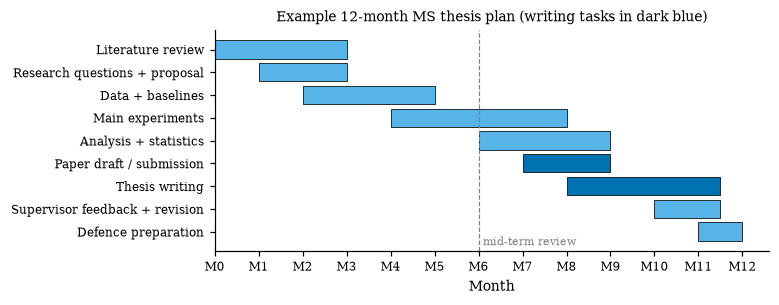

In [17]:
plan = [  # (task, start month, duration in months) for a 12-month MS research thesis (an example, not a rule)
    ("Literature review", 0, 3), ("Research questions + proposal", 1, 2), ("Data + baselines", 2, 3),
    ("Main experiments", 4, 4), ("Analysis + statistics", 6, 3), ("Paper draft / submission", 7, 2),
    ("Thesis writing", 8, 3.5), ("Supervisor feedback + revision", 10, 1.5), ("Defence preparation", 11, 1),
]
fig, ax = plt.subplots(figsize=(6.5, 2.6))
for i, (task, start, dur) in enumerate(plan):
    ax.barh(i, dur, left=start, color=OKABE_ITO[5] if "writing" in task.lower() or "draft" in task.lower()
            else OKABE_ITO[2], edgecolor="black", lw=0.5)
ax.set_yticks(range(len(plan)), [p[0] for p in plan])
ax.invert_yaxis()
ax.set_xticks(range(0, 13), [f"M{m}" for m in range(0, 13)])
ax.set_xlabel("Month"); ax.set_title("Example 12-month MS thesis plan (writing tasks in dark blue)")
ax.axvline(6, ls="--", color="grey", lw=0.8); ax.text(6.1, 8.6, "mid-term review", fontsize=7, color="grey")
plt.show()

**What just happened?** The Gantt chart shows that writing is not a final step: drafting starts while experiments are still running, and literature review continues into the proposal. Most students underestimate how long writing and revision take.

### 12.1 Working with your supervisor

- **Agree on expectations early:** meeting frequency, how quickly drafts are read, authorship on papers, target venues, the degree's publication requirements.
- **Drive the meetings yourself:** send a short agenda and your results *before* the meeting; bring concrete questions; send written notes with decisions and action items afterwards.
- **Send drafts early and often**, not one complete thesis at the end. Ask for a specific kind of feedback ("is the argument in Chapter 3 convincing?").
- **Keep a research log** (date, what you did, what you found, what failed). It helps writing and reproducibility (notebook 04).
- If problems arise (no feedback, conflicts), use your department's formal channels (graduate coordinator, co-supervisor) early.

### 12.2 The defence / viva

Formats vary by country and university. A UK-style **viva voce** is typically a closed oral examination with internal and external examiners; many other systems (including many universities in the US and Pakistan) use a **public presentation followed by questions** from a committee. Possible outcomes usually include pass, pass with minor corrections, major corrections / revise and resubmit, and (rarely) fail.

Questions you should be able to answer:
1. What is your contribution, in one sentence? What is new compared to [the closest prior work]?
2. Why did you choose this method / dataset / metric rather than [an alternative]?
3. How do you know the result is not due to chance, leakage or a weak baseline?
4. What are the limitations? What would you do with six more months?
5. Explain this equation / figure / table in detail.

> 🎓 **Exam / interview tip:** examiners often open the thesis at a random page and ask about it. Re-read the whole thesis before the defence and prepare a page of "known weaknesses" with answers.

---
## 13. Plagiarism, self-plagiarism and authorship

> 💡 **In plain English:** never present other people's words or ideas as your own, and agree early on who is an author.

**Plagiarism** is presenting someone else's words, ideas, figures, code or data as your own without proper acknowledgement. It includes:
- **verbatim copying** without quotation marks and citation;
- **patchwriting**: copying a passage and changing a few words (even *with* a citation, this is usually not acceptable; paraphrase properly or quote);
- using figures, code or data without citation/permission.

**Self-plagiarism / text recycling** means re-using your own previously published text or results without disclosure, e.g. **duplicate publication** (the same results in two venues) or **salami slicing** (splitting one study into many minimal papers). Re-using thesis material in a paper (or papers in a thesis) is usually allowed **if disclosed and permitted by the rules**; check your university and the publisher.

Universities and publishers use **similarity checkers** (e.g. Turnitin, iThenticate) that compare your text with a large database. The similarity percentage is **not** a verdict: quotes, references and common phrases also match, and an editor or supervisor interprets the report. Here is the core idea, word n-gram overlap, in a few lines:

In [18]:
def ngrams(text: str, n: int = 4) -> set:
    words = re.findall(r"[a-z0-9]+", text.lower())
    return {tuple(words[i:i + n]) for i in range(len(words) - n + 1)}


def jaccard(a: str, b: str, n: int = 4) -> float:
    """|A ∩ B| / |A ∪ B| of the word n-gram sets: 0 = nothing shared, 1 = identical."""
    A, B = ngrams(a, n), ngrams(b, n)
    return len(A & B) / len(A | B) if A | B else 0.0


source = ("Class imbalance occurs when one class is much rarer than the others. Standard training then "
          "focuses on the majority class, and the classifier rarely predicts the minority class.")
texts = {
    "verbatim copy": source,
    "patchwriting": ("Class imbalance happens when one class is much rarer than the others. Standard training "
                     "then focuses on the majority class, and the model rarely predicts the minority class."),
    "proper paraphrase + cite": ("When positive examples are scarce, a classifier trained in the usual way is "
                                 "dominated by negatives and seldom outputs the rare label (He and Garcia, 2009)."),
    "unrelated": "We measure ranking quality with the area under the precision-recall curve on five datasets.",
}
sim = pd.Series({name: jaccard(source, t) for name, t in texts.items()}, name="4-gram Jaccard vs source")
print(sim.round(2))
assert sim["verbatim copy"] == 1.0 and sim["unrelated"] == 0.0

verbatim copy               1.00
patchwriting                0.56
proper paraphrase + cite    0.00
unrelated                   0.00
Name: 4-gram Jaccard vs source, dtype: float64


**What just happened?** Copying gives similarity 1.0; patchwriting (three words changed) still shares a large part of its 4-grams with the source, so checkers flag it; a genuine paraphrase shares almost nothing even though it expresses the same idea, and **it still needs the citation**, because the idea is not yours. **Complexity:** building the n-gram sets is $O(m)$ for $m$ words, and the set intersection is $O(m)$ on average with hashing; real systems use hashed fingerprints of n-grams to compare against billions of documents quickly.

### 13.1 Authorship norms

- **Who is an author?** Someone who made a substantial intellectual contribution and takes responsibility for the paper. Medicine uses the four **ICMJE criteria** (substantial contribution; drafting or critical revision; final approval; accountability). Many journals ask for a contribution statement with the **CRediT taxonomy** (14 roles such as Conceptualization, Methodology, Software, Formal analysis, Investigation, Writing – original draft, Supervision, Funding acquisition).
- **Order in ML/CS:** usually the **first author** did most of the work (often the student); the **last author** is often the senior researcher/supervisor; equal contributions are marked with a symbol (*"* equal contribution"*). In theoretical CS, mathematics and economics, **alphabetical order** is common.
- **Not acceptable:** *gift* authorship (adding someone who did not contribute), *ghost* authorship (leaving out someone who did), and coercion.
- **Talk about authorship early**, write it down, and revisit it when contributions change. Acknowledge non-author help in the acknowledgements.

> ⚠️ **Common mistake:** copying a definition from Wikipedia or a paper "because it is just a definition". Definitions also need quotation marks or a real paraphrase, plus a citation.

---
## 14. 🔗 How this connects to modern AI

> 💡 **In plain English:** the same writing and publishing rules apply to LLM papers, model cards and industry research.

- **LLM papers and benchmarks** live and die by the same rules: clear claims, honest baselines, uncertainty over seeds/prompts, and documented evaluation details (see [LLM evaluation](../08_LLM/08_evaluation/01_llm_evaluation.ipynb)).
- **Model cards and datasheets** in your paper's appendix are the same documents that ship with models on the Hugging Face Hub ([notebook 04](04_reproducibility_and_research_code.ipynb), [Responsible AI](../19_AI_Ethics_and_Safety/04_responsible_ai.ipynb)).
- **Broader impact statements** connect to [AI ethics & safety](../19_AI_Ethics_and_Safety/01_bias_fairness.ipynb) and to [AI regulation](../19_AI_Ethics_and_Safety/05_ai_regulation_compliance.ipynb).
- **Copyright** questions about training data and AI-generated text are discussed in [Copyright and AI](../19_AI_Ethics_and_Safety/06_copyright_and_ai.ipynb).
- **Industry research labs** publish at the same venues and additionally write internal *technical reports* and *decision memos* (next notebook).

In [19]:
shutil.rmtree(WORK)                       # clean up everything we wrote
print("temporary folder removed:", not WORK.exists())

temporary folder removed: True


---
## 15. Recap

> 💡 **In plain English:** the key ideas of this notebook in a few bullet points.

- A paper is an **argument**: title and abstract (4 moves: problem, gap, approach, result), an introduction ending in **contribution bullets**, related work **by theme with contrast**, a re-implementable method, a complete setup, results **with uncertainty**, honest limitations, a short conclusion, and an ethics statement.
- Write clearly: **active voice, define terms, one name per concept, consistent notation, numbers instead of adjectives**; "significant" only with a named test.
- Maths: define every symbol, punctuate equations, use LaTeX conventions, and **check that formulas match the code**.
- Figures: final size, readable fonts, colour-blind palette **plus** markers, vector PDF with embedded fonts, error bars explained in the caption. Tables: **generated by code** (`df.to_latex`, booktabs).
- LaTeX + BibTeX: one `.bib`, many styles; `\citet` vs `\citep`; lint for missing citations and labels; Overleaf for collaboration.
- AI tools: you are responsible for everything, disclose as required, never trust generated citations, protect review confidentiality.
- Publishing: conferences dominate ML; check venue quality (CORE, SJR quartiles, h5-index, your institution's list) and avoid predatory venues; anonymise properly; answer reviewers with evidence.
- Thesis: chapters mirror a paper but with a full literature review; drive supervisor meetings; prepare the defence questions.
- No plagiarism (including patchwriting) or undisclosed text recycling; agree authorship early.

## Practice problems

**1. (Easy)** Rewrite in active voice with a concrete number: *"It was found that the accuracy was significantly improved by the proposed method."*
<details><summary>Show solution</summary>

"Our method raises accuracy from 0.84 to 0.88 (mean of 10 seeds; corrected paired t-test, p = 0.01)." The key changes: the actor ("our method", "we") is explicit, "improved" becomes a number with uncertainty, and "significantly" is replaced by a named test (or removed).
</details>

**2. (Easy)** Name the four moves of the abstract formula and write one sentence for each about a project of your own.
<details><summary>Show solution</summary>

(1) Problem/context, (2) gap, (3) what we do (approach), (4) main result + implication. Example: "(1) Urdu sentiment classifiers are needed for customer feedback, (2) but public models are trained on formal text and fail on Roman-Urdu social media posts. (3) We fine-tune a multilingual model on 20k labelled Roman-Urdu posts and compare it with three baselines over 5 seeds. (4) It improves macro-F1 by 9 points, showing that small in-domain datasets beat larger out-of-domain ones."
</details>

**3. (Medium)** A figure shows two methods with overlapping ±1 std error bars over 5 seeds. A co-author writes "no significant difference". What is wrong, and what should you do?
<details><summary>Show solution</summary>

(a) Std bars show the spread of individual runs, not the uncertainty of the mean; (b) overlapping bars are not a significance test; (c) if both methods used the same seeds/folds, the comparison is *paired* and should use the differences per seed. Do a paired test (e.g. a corrected resampled t-test for CV folds, or a paired bootstrap of the differences), report the mean difference with a CI, and say in the caption what the bars are.
</details>

**4. (Medium, coding)** Extend `anonymity_check` to flag self-references of the form *"In [12], we showed"* and *"see our technical report"*. Test it on two sentences.
<details><summary>Show solution</summary>

```python
LEAK_PATTERNS["first-person reference to a cited work"] = r"\bin \[\d+\],? we\b"
LEAK_PATTERNS["own technical report"] = r"\bour (technical )?report\b"
print(anonymity_check("In [12], we showed that weighting helps. For details see our technical report."))
# -> two rows: 'first-person reference to a cited work' and 'own technical report'
```
</details>

**5. (Medium, coding)** Modify the loop that fills `table` in Section 8 (before `reset_index`) so that the best value in each column is bold **only** if it is more than one (pooled) std above the second best; otherwise nothing is bold.
<details><summary>Show solution</summary>

```python
for d in datasets:
    ranked = pivot_mean[d].sort_values(ascending=False)
    best, second = ranked.index[0], ranked.index[1]
    gap = ranked.iloc[0] - ranked.iloc[1]
    pooled = np.sqrt((pivot_std.loc[best, d] ** 2 + pivot_std.loc[second, d] ** 2) / 2)
    for m in methods:
        table.loc[m, d] = latex_cell(pivot_mean.loc[m, d], pivot_std.loc[m, d], m == best and gap > pooled)
```
This is still a heuristic; the honest version marks results that are statistically indistinguishable from the best (e.g. with a paired test).
</details>

**6. (Medium)** Your supervisor suggests submitting to a journal that emailed you promising "acceptance within 7 days for a fee". What do you check?
<details><summary>Show solution</summary>

Signs of a predatory venue: unsolicited invitations, guaranteed fast acceptance, fees before review, vague scope, an unverifiable editorial board, and absence from recognised indexes (Scopus, Web of Science, DOAJ for OA journals) and from your institution's recognised list. Use the *Think. Check. Submit.* checklist and ask your library. A real 7-day peer review with fees is a strong red flag.
</details>

**7. (Hard, coding)** Is the `jaccard` checker fooled by reordering sentences? Swap the two sentences of `source`, compute the 4-gram similarity, and explain the result. Then replace every fifth word with a different word and compare.
<details><summary>Show solution</summary>

```python
sents = re.split(r"(?<=\.)\s+", source)
print(round(jaccard(source, " ".join(reversed(sents))), 2))        # 0.79: still high
words = source.split()
edited = " ".join(f"word{i}" if i % 5 == 4 else w for i, w in enumerate(words))
print(round(jaccard(source, edited), 2))                            # 0.11: much lower
```
Reordering keeps every 4-gram inside each sentence; only the few 4-grams that cross the sentence border change, so the similarity stays high (0.79) and the copy is still detected. Replacing every fifth word leaves only one 4-gram window in five untouched, so the similarity drops to about 0.1. That is why real checkers also use shorter n-grams, fingerprints that are robust to small edits and, increasingly, semantic (embedding) similarity, and why a human always interprets the report.
</details>

**8. (Hard)** Write the contribution bullets and the limitations paragraph for a study you know (your thesis or a paper you read). Then check each bullet: which figure/table supports it?
<details><summary>Show solution</summary>

There is no single answer. A good result has 2–4 bullets, each a *verifiable* statement ("We show X on Y with Z") that points to one table/figure, and a limitations paragraph that names data, model-class, metric and compute limits plus at least one condition where the method is expected to fail. If a bullet has no supporting figure/table, either add the evidence or remove the bullet.
</details>

## Further reading

- Justin Zobel, *Writing for Computer Science*, 3rd ed., Springer, 2014 (style, maths, figures, ethics).
- Wayne C. Booth, Gregory G. Colomb, Joseph M. Williams et al., *The Craft of Research*, University of Chicago Press (research questions and argument).
- Simon Peyton Jones, *How to write a great research paper* (talk and slides, free online).
- Zachary C. Lipton and Jacob Steinhardt, *Troubling Trends in Machine Learning Scholarship* (2018, arXiv:1807.03341): overclaiming, mathiness, misuse of language.
- COPE (Committee on Publication Ethics) guidance on authorship, AI tools and text recycling: https://publicationethics.org
- The current call for papers, author guidelines and LLM policy of your target venue (read them every cycle).

## Next notebook

➡️ [06 🏭 Industry project: running a research project end to end](06_industry_running_a_research_project_end_to_end.ipynb): you will run the class-balancing study used as the example here, with pre-registration, nested CV, statistical tests, publication figures, a LaTeX table and a reproducibility package.